In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_rfm = pd.read_csv(
    "../output/customer_rfm.csv",
    dtype={"Customer ID": "string"}
)

print("Kích thước:", df_rfm.shape)
print(df_rfm.head(10).to_string(index=False))
print("\nGiá trị thiếu:")
print(df_rfm.isna().sum().to_string())

Kích thước: (5878, 4)
Customer ID  Recency  Frequency  Monetary
      12346      326         12  77556.46
      12347        3          8   4921.53
      12348       76          5   2019.40
      12349       19          4   4428.69
      12350      311          1    334.40
      12351      376          1    300.93
      12352       37         10   2849.84
      12353      205          2    406.76
      12354      233          1   1079.40
      12355      215          2    947.61

Giá trị thiếu:
Customer ID    0
Recency        0
Frequency      0
Monetary       0


In [2]:
features = ["Recency", "Frequency", "Monetary"]

skewness = df_rfm[features].skew()

print("Độ lệch (Skewness) của các đặc trưng:")
print(skewness.round(3).to_string())

Độ lệch (Skewness) của các đặc trưng:
Recency       0.887
Frequency    12.640
Monetary     25.070


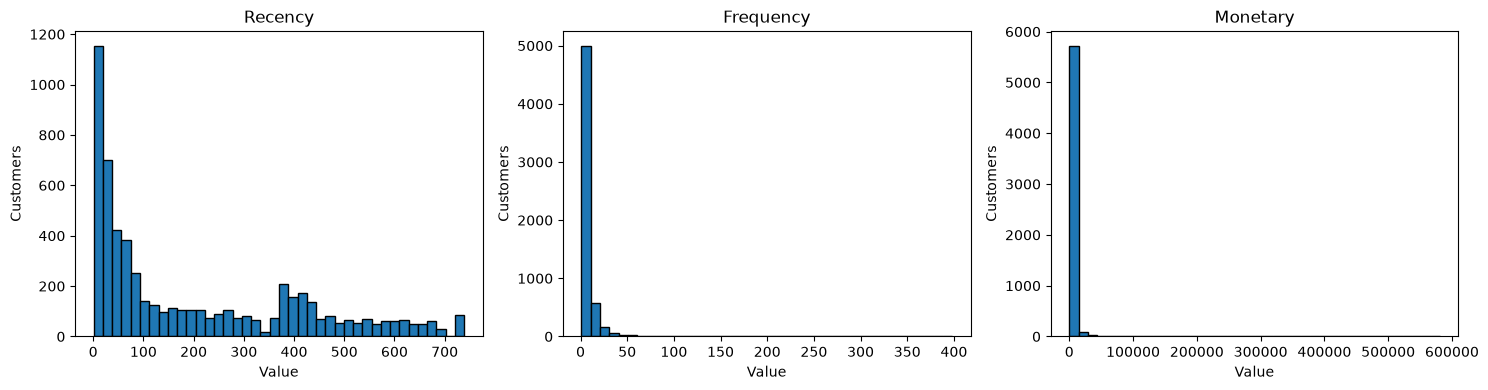

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features):
    ax.hist(df_rfm[feature], bins=40, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Customers")

plt.tight_layout()

plt.savefig(
    "../output/rfm_distribution_before.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Tạo bản sao để giữ nguyên dữ liệu RFM gốc
df_rfm_log = df_rfm.copy()

# Biến đổi logarithm cho hai đặc trưng lệch phải mạnh
df_rfm_log["Frequency"] = np.log1p(df_rfm["Frequency"])
df_rfm_log["Monetary"] = np.log1p(df_rfm["Monetary"])

# So sánh độ lệch trước và sau biến đổi
skew_comparison = pd.DataFrame({
    "Before": df_rfm[features].skew(),
    "After": df_rfm_log[features].skew()
})

print("SO SÁNH SKEWNESS TRƯỚC VÀ SAU LOG")
print(skew_comparison.round(3).to_string())

SO SÁNH SKEWNESS TRƯỚC VÀ SAU LOG
           Before  After
Recency     0.887  0.887
Frequency  12.640  1.001
Monetary   25.070  0.269


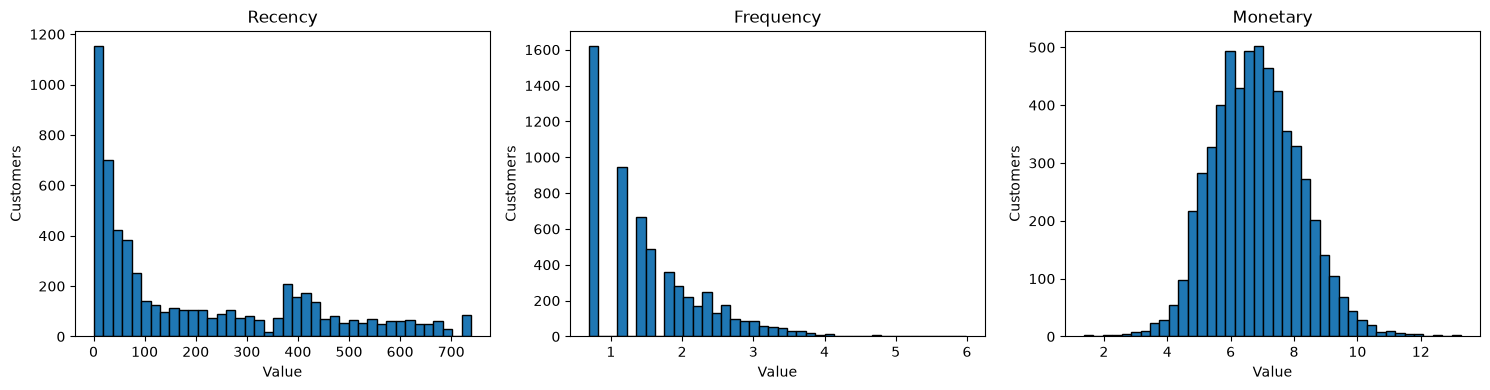

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features):
    ax.hist(
        df_rfm_log[feature],
        bins=40,
        edgecolor="black"
    )

    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Customers")

plt.tight_layout()

plt.savefig(
    "../output/rfm_distribution_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()